# P4 — Analyse croisée météo × pollution × vélos

**Source** : couche silver `silver/croise/` — 1 ligne par **ville × heure UTC** (525 888 lignes, 12 villes,
01/11/2021 → 31/10/2026) réunissant les trois sources. Météo × pollution : **5 ans** ; avec les vélos :
**novembre 2024 → septembre 2026**.

**Méthode clé : l'indice relatif.** Comparer directement « pollution et vent » ou « vélo et température » mélange
les cycles : la nuit, il y a moins de vent, plus de NO2, moins de vélos et il fait plus frais ; l'hiver, plus de
particules et moins de soleil. Chaque mesure est donc rapportée à la **normale de la même ville, du même mois (ou de
la même saison pour le vélo) et de la même heure locale** : indice 1 = normal, 1,3 = 30 % au-dessus. Les écarts
d'indice mesurent l'effet de la météo **à heure et saison égales**.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common.storage import get_storage
from common.silver import read_silver
from common import viz
from p4_croise import analytics as a

viz.apply_style()
pd.set_option("display.width", 160)
df = read_silver(get_storage(), "silver/croise/")
pol = a.pollution_indices(df)
v = a.velo_frame(df)
three = df["a_meteo"] & df["a_pollution"] & df["a_velos"]
print(f"{len(df):,} lignes ville × heure · {int(df['a_pollution'].sum()):,} avec pollution · "
      f"{len(v):,} heures vélo indexées · {int(three.sum()):,} heures avec les 3 sources")

def bars(ax, labels, values, title, ref=1.0, fmt="{:.2f}"):
    ax.bar(range(len(values)), values, color=viz.BLUE, width=0.65)
    ax.axhline(ref, color=viz.INK_2, lw=1, ls="--")
    ax.set_xticks(range(len(values)), labels, rotation=0)
    for x, val in enumerate(values):
        ax.text(x, val + 0.02, fmt.format(val), ha="center", fontsize=8, color=viz.INK_2)
    ax.set_title(title); ax.grid(axis="x", visible=False)

525,888 lignes ville × heure · 367,328 avec pollution · 186,519 heures vélo indexées · 148,888 heures avec les 3 sources


## Q1 — Météo ↔ pollution (5 ans)

Quatre mécanismes testés : **dispersion par le vent**, **lessivage par la pluie**, **stagnation hivernale**
(anticyclone + vent faible, propice aux inversions de température) et **formation d'ozone par la chaleur**.

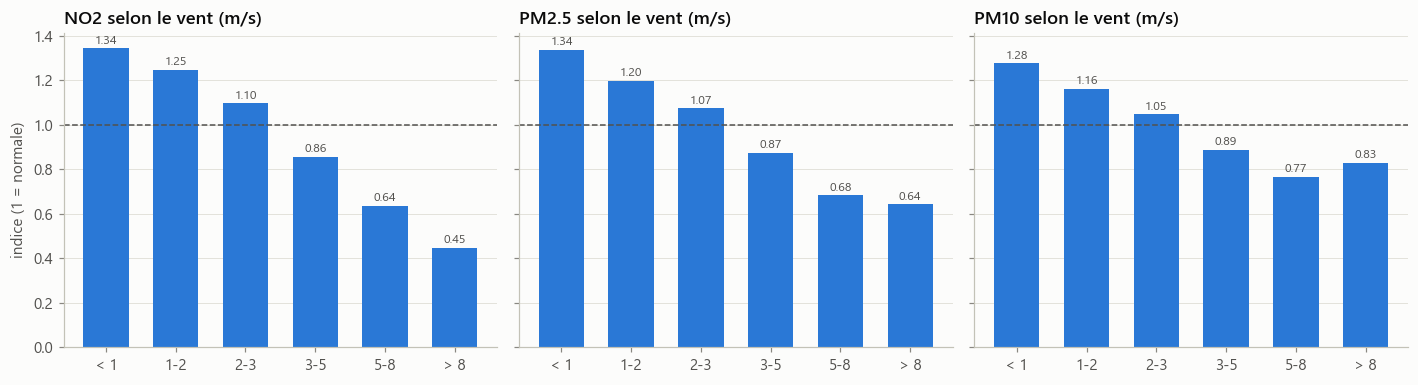

Lessivage — indice moyen d'une JOURNÉE selon sa pluie :


,i_pm25,i_pm10,i_no2
type_jour,,,
"sec (< 0,2 mm)",1.137,1.127,1.083
"pluvieux (0,2-5 mm)",0.852,0.856,0.913
très pluvieux (> 5 mm),0.732,0.732,0.840


Stagnation hivernale (déc.-fév.) — indice PM2.5 :


vent,vent < 2 m/s,vent ≥ 2 m/s
pression,,
haute pression (≥ 1025 hPa),1.58,1.10
pression < 1025 hPa,1.34,0.73


In [2]:
wl = ["< 1", "1-2", "2-3", "3-5", "5-8", "> 8"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, p in zip(axes, ["i_no2", "i_pm25", "i_pm10"]):
    b = a.binned(pol, "vent_ms", p, a.WIND_BINS)
    bars(ax, wl, b["moyenne"].values, f"{p[2:].upper().replace('PM25', 'PM2.5')} selon le vent (m/s)")
axes[0].set_ylabel("indice (1 = normale)")
plt.tight_layout(); plt.show()
print("Lessivage — indice moyen d'une JOURNÉE selon sa pluie :"); display(a.rain_washout(df))
print("Stagnation hivernale (déc.-fév.) — indice PM2.5 :"); display(a.stagnation(df))

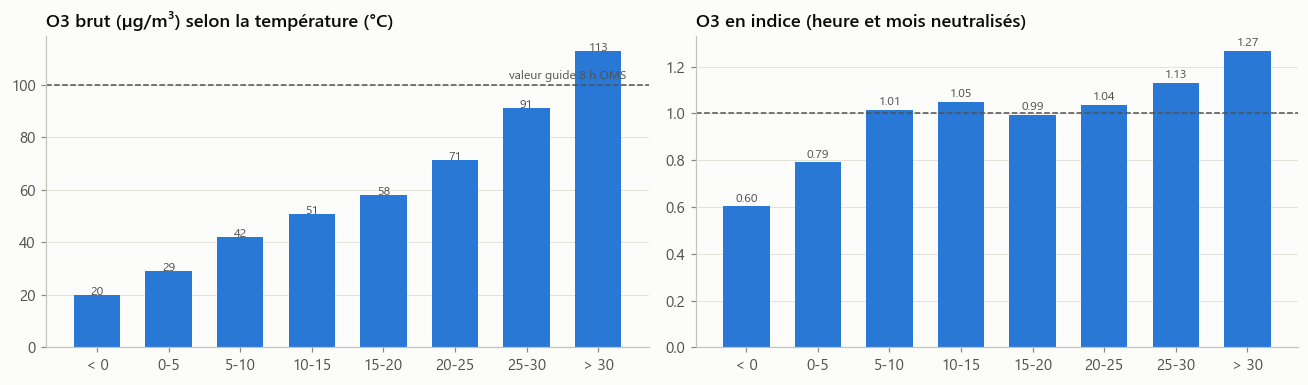

Corrélations de Spearman entre indices de pollution et météo :


,temperature_c,vent_ms,precipitation_mm,humidite_pct,pression_hpa
i_pm25,0.05,-0.35,-0.21,0.00,0.26
i_pm10,0.06,-0.30,-0.25,-0.06,0.26
i_no2,-0.06,-0.47,-0.13,0.04,0.19
i_o3,0.17,0.41,0.09,-0.26,-0.21


In [3]:
tl = ["< 0", "0-5", "5-10", "10-15", "15-20", "20-25", "25-30", "> 30"]
raw = a.binned(pol, "temperature_c", "o3", a.TEMP_BINS)
idx = a.binned(pol, "temperature_c", "i_o3", a.TEMP_BINS)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
bars(axes[0], tl, raw["moyenne"].values, "O3 brut (µg/m³) selon la température (°C)", ref=100, fmt="{:.0f}")
axes[0].text(7.4, 101, "valeur guide 8 h OMS", fontsize=8, color=viz.INK_2, ha="right", va="bottom")
bars(axes[1], tl, idx["moyenne"].values, "O3 en indice (heure et mois neutralisés)")
plt.tight_layout(); plt.show()
print("Corrélations de Spearman entre indices de pollution et météo :"); display(a.spearman_indices(df))

**Conclusion Q1.**
- **Le vent disperse la pollution.** Par vent calme (< 1 m/s), le NO2 est **34 % au-dessus de sa normale** ; par
  vent fort (> 8 m/s), **55 % en dessous** — le NO2 est divisé par 3. Les PM2.5 sont divisées par 2 (indice 1,34 →
  0,64). C'est la relation la plus forte (Spearman −0,47 pour le NO2).
- **La pluie lave l'air.** Un jour très pluvieux (> 5 mm) a des PM2.5 et PM10 **≈ 36 % plus bas** qu'un jour sec
  (indice 0,73 contre 1,14), et un NO2 22 % plus bas.
- **L'hiver anticyclonique piège les particules.** Haute pression + vent faible : PM2.5 **58 % au-dessus de la
  normale** ; dépression ventée : 27 % en dessous — un facteur **2,2** entre les deux situations. C'est le scénario
  des épisodes de janvier 2024 vus en P3.
- **La chaleur fabrique l'ozone.** L'O3 passe de 20 µg/m³ sous 0 °C à **113 µg/m³ au-dessus de 30 °C** — au-dessus
  de la valeur guide de l'OMS. Même à heure et saison égales, il reste **27 % au-dessus de la normale** par plus de
  30 °C : c'est ce qui explique que les épisodes d'ozone de P3 coïncident avec les vagues de chaleur de P1.
  L'ozone augmente aussi avec le vent (+0,41), qui disperse le NO2 qui le détruit en ville.

## Q2 — Météo ↔ usage du vélo

Heures avec vélos (novembre 2024 → septembre 2026). Activité exprimée en **indice** par rapport à la normale de la
même ville, saison, heure locale et type de jour (ouvré / week-end). Effet de la pluie mesuré en journée (7 h-21 h).

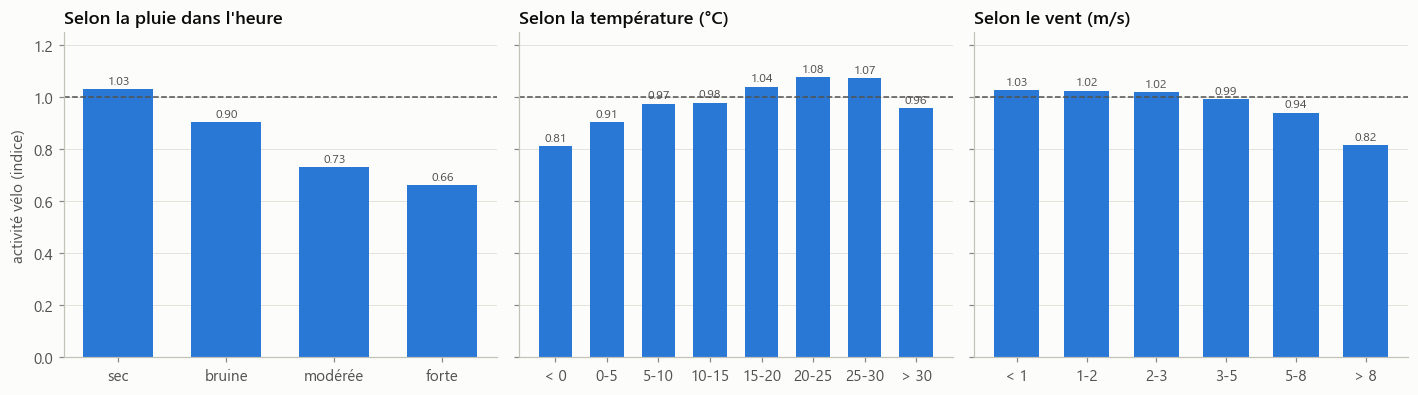

Jours secs / pluvieux (indice moyen de la journée) :


mean  size
type_jour     weekend             
pluvieux      False    0.988  1740
              True     0.988   696
sec           False    1.032  3068
              True     1.047  1178
très pluvieux False    0.885   769
              True     0.856   360

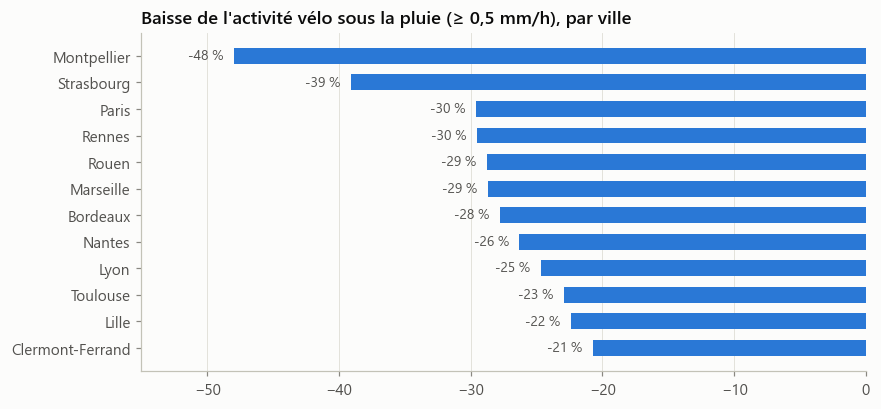

In [4]:
day = v[v["heure_locale"].between(7, 20)]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7), sharey=True)
r = a.rain_effect(v)
bars(axes[0], ["sec", "bruine", "modérée", "forte"], r["moyenne"].values, "Selon la pluie dans l'heure")
t = a.binned(day, "temperature_c", "i_velo", a.TEMP_BINS)
bars(axes[1], tl, t["moyenne"].values, "Selon la température (°C)")
w = a.binned(day, "vent_ms", "i_velo", a.WIND_BINS)
bars(axes[2], wl, w["moyenne"].values, "Selon le vent (m/s)")
axes[0].set_ylabel("activité vélo (indice)"); axes[0].set_ylim(0, 1.25)
plt.tight_layout(); plt.show()
print("Jours secs / pluvieux (indice moyen de la journée) :"); display(a.dry_vs_rainy_days(v))
eff = a.rain_effect_by_city(v)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.barh(eff.index.str.title()[::-1], eff["effet_pluie_pct"][::-1], color=viz.BLUE, height=0.6)
for y, val in enumerate(eff["effet_pluie_pct"][::-1]):
    ax.text(val - 0.8, y, f"{val:.0f} %", va="center", ha="right", fontsize=9, color=viz.INK_2)
ax.set_xlim(-55, 0); ax.set_title("Baisse de l'activité vélo sous la pluie (≥ 0,5 mm/h), par ville")
ax.grid(axis="y", visible=False); plt.show()

**Conclusion Q2.**
- **La pluie est le facteur météo le plus fort.** À heure égale, l'activité baisse de **12 % sous la bruine**, de
  **29 % sous une pluie modérée** et de **36 % sous une forte pluie**. Une journée très pluvieuse fait perdre environ
  **14 % d'activité en semaine et 18 % le week-end** (les trajets de loisir sont plus facilement annulés).
- **La température a un optimum** : activité la plus haute entre **20 et 30 °C** (+7-8 %), **−19 % par temps de
  gel** (< 0 °C) et une baisse au-delà de 30 °C (−4 %).
- **Le vent ne compte qu'au-delà de 5 m/s** (≈ 18 km/h) : −6 %, puis **−18 % au-delà de 8 m/s**.
- La sensibilité à la pluie dépend de la ville : **Montpellier (−48 %) et Strasbourg (−39 %)**, où l'usage est plus
  « loisir », réagissent le plus ; **Clermont-Ferrand (−21 %) et Lille (−22 %)**, où le vélo est un mode de
  déplacement habituel (et où il pleut souvent), le moins.

## Q3 — Conditions favorables à la mobilité douce

**Score de favorabilité** (0 à 3) : +1 si la température est entre **10 et 25 °C**, +1 s'il **ne pleut pas**,
+1 si le **vent est sous 5 m/s**. On le **valide** avec l'activité réellement observée, puis on l'applique aux
5 ans de météo pour comparer les villes.

,indice_activite,heures
score,,
0,0.809,1698
1,0.869,11783
2,0.976,51768
3,1.071,43541


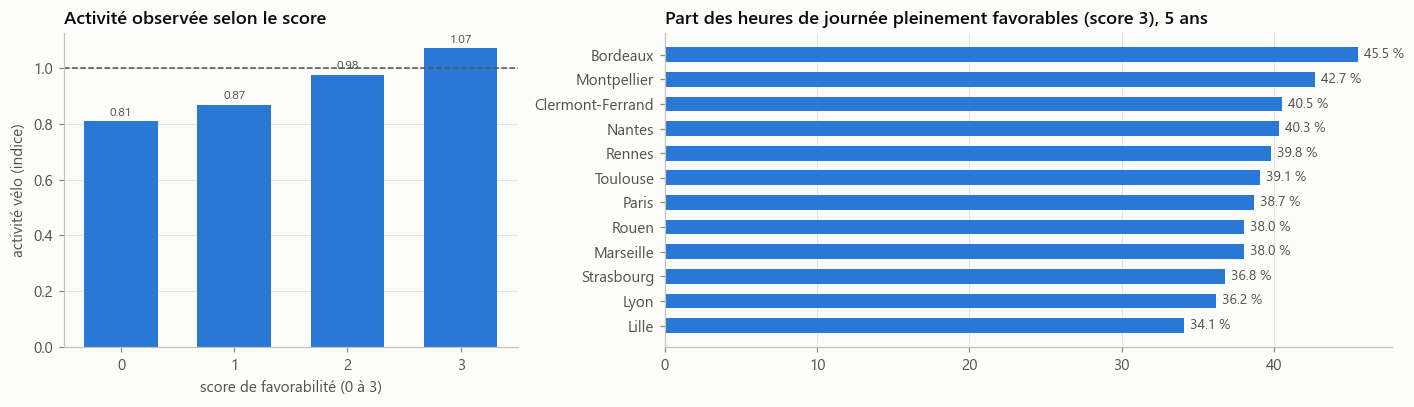

In [5]:
val = a.favorability_validation(v)
display(val)
fav = a.favorable_share(df)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
bars(axes[0], [str(i) for i in val.index], val["indice_activite"].values, "Activité observée selon le score")
axes[0].set_xlabel("score de favorabilité (0 à 3)"); axes[0].set_ylabel("activité vélo (indice)")
f = fav["pct_heures_favorables"].sort_values()
axes[1].barh(f.index.str.title(), f.values, color=viz.BLUE, height=0.6)
for y, val_ in enumerate(f.values):
    axes[1].text(val_ + 0.4, y, f"{val_:.1f} %", va="center", fontsize=9, color=viz.INK_2)
axes[1].set_title("Part des heures de journée pleinement favorables (score 3), 5 ans")
axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Conclusion Q3.**
- **Le score est validé par les usagers** : l'activité augmente régulièrement avec lui — **indice 0,81 (score 0) →
  0,87 → 0,98 → 1,07 (score 3)**, soit **32 % d'activité en plus** entre les conditions les plus défavorables et
  les plus favorables.
- Sur 5 ans, **Bordeaux (45,5 %) et Montpellier (42,7 %)** offrent le plus d'heures de journée pleinement
  favorables ; **Lille (34,1 %), Lyon (36,2 %) et Strasbourg (36,8 %)** le moins (froid l'hiver, chaleur l'été à
  Lyon, vent et pluie à Lille).
- Paradoxe utile pour les décideurs : **les villes les plus favorables par la météo ne sont pas celles où l'on roule
  le plus** (Montpellier a l'usage le plus faible en P2, Lyon le plus fort) : **l'infrastructure et la taille du
  réseau comptent davantage que le climat**.

## Q4 — Interactions fortes et modèle explicatif

1. **Coïncidences** : jours où une **pollution élevée** (PM2.5 > 15 µg/m³ ou O3 > 120 µg/m³), une **météo
   défavorable** (≥ 5 mm de pluie, T max ≥ 30 °C ou ≤ 3 °C, vent ≥ 6 m/s) et un **usage vélo atypique** (indice
   < 0,75 ou > 1,25) se produisent ensemble.
2. **Modèle explicatif** (gradient boosting) de l'activité vélo horaire, **évalué sur la période la plus récente**
   (20 % des données, jamais vues à l'entraînement), avec l'**importance par permutation** de chaque facteur.

In [6]:
cd = a.combined_days(df, v)
triple = cd[cd["pollution_elevee"] & cd["meteo_defavorable"] & cd["velo_atypique"]]
print(f"{len(cd):,} jours ville avec vélos · {len(triple)} jours avec les 3 conditions réunies")
print("Usage atypique selon la pollution (part des jours) :")
display(pd.crosstab(cd["pollution_elevee"], cd["velo_atypique"], normalize="index").round(3))
print("Dates (jour-mois) les plus fréquentes parmi les coïncidences :",
      triple["date_locale"].str[5:].value_counts().head(6).to_dict())
display(triple.sort_values("i_velo").head(6)[["ville_id", "date_locale", "pm25", "o3_max", "t_max", "pluie", "i_velo"]].round(1))

7,811 jours ville avec vélos · 187 jours avec les 3 conditions réunies
Usage atypique selon la pollution (part des jours) :


velo_atypique,False,True
pollution_elevee,,
False,0.707,0.293
True,0.676,0.324


Dates (jour-mois) les plus fréquentes parmi les coïncidences : {'06-21': 7, '12-26': 7, '12-29': 5, '07-10': 5, '05-28': 5, '06-22': 5}


,ville_id,date_locale,pm25,o3_max,t_max,pluie,i_velo
6622,strasbourg,2025-03-12,34.9,58.7,7.4,10.1,0.3
2020,lyon,2024-12-26,28.9,14.9,2.4,0.0,0.3
6878,strasbourg,2025-11-23,20.7,45.2,2.5,4.9,0.3
2023,lyon,2024-12-29,25.1,11.1,1.0,0.0,0.3
2025,lyon,2024-12-31,28.0,6.6,2.7,0.0,0.4
2024,lyon,2024-12-30,17.1,23.0,0.3,0.0,0.4


Modèle de l'activité horaire : R² = 0.683 sur la période test (depuis 2026-04-14), erreur moyenne 0.921 mouvement / station / heure


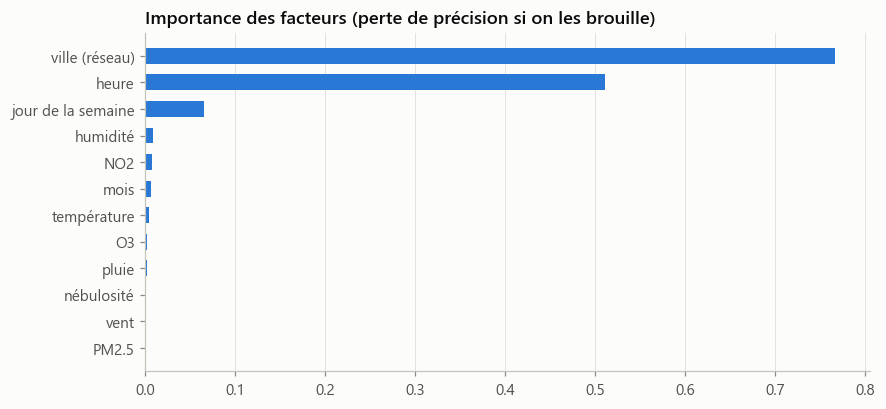

Modèle de l'ÉCART à la normale (météo + pollution seules) : R² = -0.0 sur la période test


In [7]:
res = a.explain_activity(v, "activite_par_station")
print(f"Modèle de l'activité horaire : R² = {res['r2']} sur la période test (depuis {res['test_depuis'][:10]}), "
      f"erreur moyenne {res['mae']} mouvement / station / heure")
imp = res["importance"].clip(lower=0)
noms = {"ville_code": "ville (réseau)", "heure_locale": "heure", "jour_semaine": "jour de la semaine", "mois": "mois",
        "temperature_c": "température", "precipitation_mm": "pluie", "vent_ms": "vent", "humidite_pct": "humidité",
        "nebulosite_pct": "nébulosité", "pm25": "PM2.5", "no2": "NO2", "o3": "O3"}
imp.index = [noms[i] for i in imp.index]
fig, ax = plt.subplots(figsize=(8.5, 4))
s = imp.sort_values()
ax.barh(s.index, s.values, color=viz.BLUE, height=0.6)
ax.set_title("Importance des facteurs (perte de précision si on les brouille)"); ax.grid(axis="y", visible=False)
plt.show()
res2 = a.explain_activity(v, "i_velo")
print(f"Modèle de l'ÉCART à la normale (météo + pollution seules) : R² = {res2['r2']} sur la période test")

**Conclusion Q4.**
- **Les coïncidences sont rares (187 jours ville sur 7 811) et s'expliquent par le calendrier ou la canicule.** Les
  dates qui reviennent sont le **21 juin** (Fête de la musique, pendant la vague de chaleur de 2026), **les 26-29
  décembre** (vacances de Noël, en pleine saison des particules fines), puis **le 10 juillet et le 28 mai** (vagues de
  chaleur 2026, donc ozone élevé) : ce sont le **calendrier** et les **épisodes de chaleur** qui font coïncider
  pollution, météo et usage atypique.
- **La pollution ne fait pas fuir les cyclistes** : un jour pollué n'a presque pas plus de chances d'avoir un usage
  atypique qu'un jour normal (≈ 32 % contre 29 %).
- **Le modèle explique 68 % de l'activité horaire**, mais presque entièrement par **le réseau (la ville) et l'heure
  de la journée** ; la météo et la pollution ne pèsent qu'à la marge.
- Pour l'**écart à la normale**, la météo seule ne permet pas de **prédire** la période suivante (R² ≈ 0) : ses
  effets sont réels **en moyenne** (Q2), mais les variations d'un jour à l'autre dépendent surtout de facteurs absents
  de nos données — **vacances, jours fériés, événements, grèves, évolution du réseau**. Les intégrer est la piste
  d'amélioration n° 1 pour le modèle ML.

## Synthèse P4

| Croisement | Effet mesuré (à heure et saison égales) |
|---|---|
| Vent → pollution | NO2 ÷ 3 et PM2.5 ÷ 2 entre vent calme et vent fort |
| Pluie → pollution | particules −36 % un jour très pluvieux (lessivage) |
| Anticyclone hivernal → particules | PM2.5 × 2,2 entre « haute pression + calme » et « dépression ventée » |
| Chaleur → ozone | 113 µg/m³ au-dessus de 30 °C (> valeur guide OMS) ; +27 % même à saison égale |
| Pluie → vélo | −12 % (bruine) à −36 % (forte pluie) ; −14 à −18 % sur une journée très pluvieuse |
| Température → vélo | optimum 20-30 °C ; −19 % par temps de gel |
| Conditions favorables | +32 % d'activité entre score 0 et score 3 ; Bordeaux et Montpellier les plus favorables |
| Pollution → vélo | pas d'effet notable ; coïncidences dues au calendrier |

*Limites* : période commune aux 3 sources limitée (nov. 2024 → sept. 2026) ; corrélations et non causalités ;
pas de données de calendrier (vacances, fériés, événements) ; Nantes peu couverte pour la pollution.